# Tarea 2: Inteligencia Artificial — Regresión lineal, Ridge y Lasso

**Estudiantes:** Laura Ruidiaz y Angelo Maiale

**Dataset:** autos usados del portal CarDekho (India), descargado de Kaggle. Son datos reales y la variable objetivo es `selling_price` (precio en rupias).

| Punto | Contenido |
|---|---|
| 1 | Exploración, limpieza y sobreajuste con `LinearRegression` |
| 2 | Clase `MyRidge` (archivo `my_ridge.py`) |
| 3 | Corrección del sobreajuste con `MyRidge` y verificación con sklearn |
| 4 | Ridge vs. Lasso |

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning

from my_ridge import MyRidge          # Punto 2: nuestra clase (solo NumPy)

RANDOM_STATE = 42                     # misma semilla en todo el notebook para que sea reproducible

## Punto 1 — Exploración, limpieza y sobreajuste (4 puntos)

### 1.1 Exploración breve

In [2]:
# Cargar el dataset desde la carpeta data/
df = pd.read_csv("data/dataset.csv")
print("--- Dimensiones originales del dataset ---")
print(df.shape)
print("\n--- Primeras filas ---")
print(df.head())

--- Dimensiones originales del dataset ---
(8128, 12)

--- Primeras filas ---
                           name  year  selling_price  km_driven    fuel  \
0        Maruti Swift Dzire VDI  2014         450000     145500  Diesel   
1  Skoda Rapid 1.5 TDI Ambition  2014         370000     120000  Diesel   
2      Honda City 2017-2020 EXi  2006         158000     140000  Petrol   
3     Hyundai i20 Sportz Diesel  2010         225000     127000  Diesel   
4        Maruti Swift VXI BSIII  2007         130000     120000  Petrol   

  seller_type transmission         owner  mileage(km/ltr/kg)  engine  \
0  Individual       Manual   First Owner               23.40  1248.0   
1  Individual       Manual  Second Owner               21.14  1498.0   
2  Individual       Manual   Third Owner               17.70  1497.0   
3  Individual       Manual   First Owner               23.00  1396.0   
4  Individual       Manual   First Owner               16.10  1298.0   

  max_power  seats  
0        74    5.

In [3]:
print("--- Tipos de datos ---")
print(df.dtypes)
print("\n--- Valores faltantes por columna ---")
print(df.isnull().sum())
print(f"\nFilas duplicadas: {df.duplicated().sum()}")
print("\n--- Estadísticas del precio de venta ---")
print(df["selling_price"].describe().round(0))

--- Tipos de datos ---
name                      str
year                    int64
selling_price           int64
km_driven               int64
fuel                      str
seller_type               str
transmission              str
owner                     str
mileage(km/ltr/kg)    float64
engine                float64
max_power                 str
seats                 float64
dtype: object

--- Valores faltantes por columna ---
name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64

Filas duplicadas: 1202

--- Estadísticas del precio de venta ---
count        8128.0
mean       638272.0
std        806253.0
min         29999.0
25%        254999.0
50%        450000.0
75%        675000.0
max      10000000.0
Name: selling

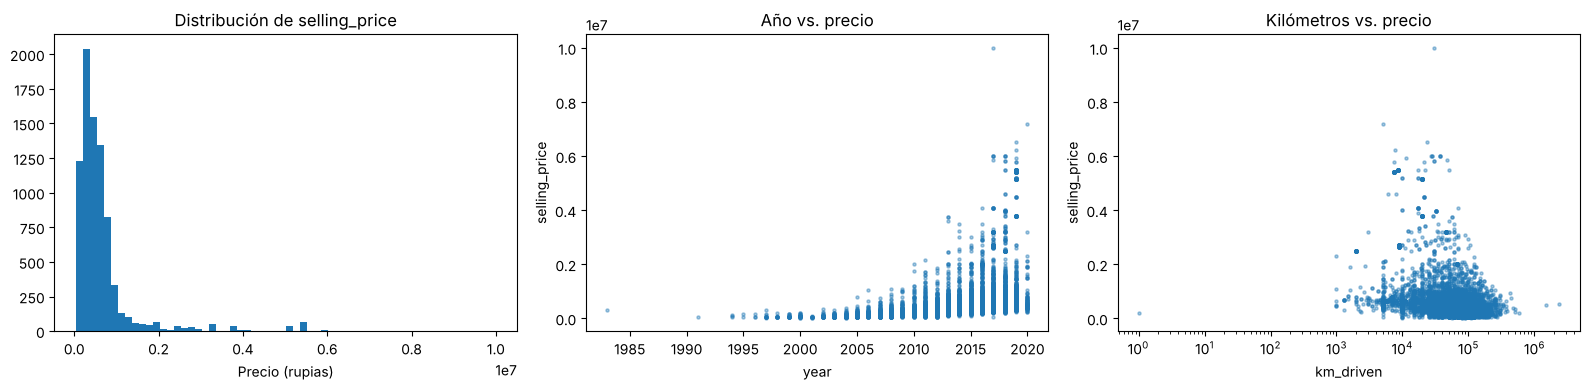

In [4]:
# Distribución del precio y relación con dos features
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(df["selling_price"], bins=60)
axes[0].set_title("Distribución de selling_price")
axes[0].set_xlabel("Precio (rupias)")
axes[1].scatter(df["year"], df["selling_price"], s=5, alpha=0.4)
axes[1].set_title("Año vs. precio")
axes[1].set_xlabel("year")
axes[2].scatter(df["km_driven"], df["selling_price"], s=5, alpha=0.4)
axes[2].set_title("Kilómetros vs. precio")
axes[2].set_xlabel("km_driven")
axes[2].set_xscale("log")
for ax in axes[1:]:
    ax.set_ylabel("selling_price")
plt.tight_layout()
plt.show()

**Hallazgos**

- 8.128 autos y 12 columnas. `max_power` viene como texto y hay unas 220 filas con faltantes.
- El precio es muy asimétrico: la mediana es de 450 mil, pero hay autos de hasta 10 millones.
- Los autos más nuevos valen más, y los que tienen más kilómetros, menos.

### 1.2 Limpieza y sobreajuste forzado

- **Limpieza:** se eliminan los faltantes y `max_power` se convierte a número.
- **8 features cuantitativas:** las 6 numéricas más `km_per_year` (intensidad de uso) y `engine_power_ratio` (cilindrada / potencia).
- **Sobreajuste:** se entrena con solo **35 autos** y se usa `PolynomialFeatures(degree=3)`, que convierte las 8 features en **164**. Con más features que ejemplos, el modelo puede memorizar el entrenamiento.

In [5]:
# Limpieza de valores nulos
df = df.dropna().copy()

# Asegurar que max_power sea numérico (los textos no convertibles pasan a NaN y se eliminan)
df["max_power"] = pd.to_numeric(df["max_power"], errors="coerce")
df = df.dropna().copy()

# Features cuantitativas adicionales para cumplir con el requisito de al menos 8 variables numéricas
df["km_per_year"] = df["km_driven"] / (2026 - df["year"] + 1)
df["engine_power_ratio"] = df["engine"] / (df["max_power"] + 1e-5)

# Features predictoras (8 cuantitativas) y target continuo (selling_price)
feature_cols = ["year", "km_driven", "mileage(km/ltr/kg)", "engine", "max_power", "seats", "km_per_year", "engine_power_ratio"]
X = df[feature_cols].values
y = df["selling_price"].values
print(f"Filas después de limpiar: {len(df)}")

# Split con un conjunto de entrenamiento muy pequeño para forzar el sobreajuste
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=35, random_state=RANDOM_STATE)

# Expandir características con PolynomialFeatures (grado 3) para disparar la complejidad
poly = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
feature_names_poly = poly.get_feature_names_out(feature_cols)
print(f"Entrenamiento: {X_train_poly.shape[0]} ejemplos x {X_train_poly.shape[1]} features | Prueba: {X_test_poly.shape[0]} ejemplos")

# Entrenar regresión lineal de sklearn
lr = LinearRegression()
lr.fit(X_train_poly, y_train)

# Calcular RMSE
rmse_train_p1 = np.sqrt(mean_squared_error(y_train, lr.predict(X_train_poly)))
rmse_test_p1 = np.sqrt(mean_squared_error(y_test, lr.predict(X_test_poly)))

print("\n=== RESULTADOS PUNTO 1 ===")
print(f"RMSE de entrenamiento: {rmse_train_p1:,.0f}")
print(f"RMSE de prueba:        {rmse_test_p1:,.0f}")
print(f"El error de prueba es {rmse_test_p1 / rmse_train_p1:,.0f} veces el de entrenamiento")

Filas después de limpiar: 7906
Entrenamiento: 35 ejemplos x 164 features | Prueba: 7871 ejemplos

=== RESULTADOS PUNTO 1 ===
RMSE de entrenamiento: 471,493
RMSE de prueba:        219,252,792
El error de prueba es 465 veces el de entrenamiento


**Resultado: sobreajuste claro.** El RMSE de prueba (≈ 219 millones) es unas **465 veces** el de entrenamiento (≈ 471 mil). El modelo memorizó los 35 autos con coeficientes enormes que fallan con autos nuevos: es **alta varianza**.

## Punto 2 — Clase `MyRidge` (8 puntos)

**Idea.** Ridge agrega a la regresión lineal una penalización al tamaño de los coeficientes:

$$J(\theta) = \lVert y - X\theta \rVert^2 + \lambda \lVert \theta \rVert^2$$

Si λ = 0, es la regresión lineal normal. Un λ grande encoge los coeficientes y da un modelo más simple, con menos varianza.

**Solución cerrada.** Se deriva J, se iguala a 0 y se despeja:

$$\theta = (X^T X + \lambda I)^{-1} X^T y$$

Sumar λI hace que la matriz siempre sea invertible, aunque haya más features que ejemplos.

**El intercepto no se penaliza.** Solo ubica el nivel promedio, no causa sobreajuste. Para dejarlo fuera:

1. En `fit` se calculan y guardan las medias `X_mean_` e `y_mean_`.
2. Se restan esas medias a X e y, y se resuelve la ecuación **sin columna de unos**.
3. Se recupera el intercepto: $\theta_0 = \bar{y} - \bar{x}^T\theta$.

**Detalles clave**

- Se usa `np.linalg.solve` en vez de `inv` porque es más estable numéricamente.
- `predict` usa siempre las medias guardadas en `fit`. Usar las de los datos nuevos sería fuga de información.
- `score` calcula R² y `rmse` la raíz del error cuadrático medio.

**Dónde está cada cosa en `my_ridge.py`**

| Paso | Línea clave |
|---|---|
| Medias | `self.X_mean_ = X.mean(axis=0)` |
| Centrado | `Xc = X - self.X_mean_` |
| Sistema | `np.linalg.solve(Xc.T @ Xc + alpha * I, Xc.T @ yc)` |
| Intercepto | `self.intercept_ = self.y_mean_ - self.X_mean_ @ self.coef_` |
| Predicción | `(X - self.X_mean_) @ self.coef_ + self.y_mean_` |

In [6]:
# Ejemplo de uso de la clase, como en el enunciado, con las 8 features originales (sin estandarizar)
model = MyRidge(alpha=1.0)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("coef_      :", np.round(model.coef_, 2))
print("intercept_ :", round(model.intercept_, 2))
print("X_mean_    :", np.round(model.X_mean_, 2))
print("y_mean_    :", round(model.y_mean_, 2))
print(f"Entrenamiento  R² = {model.score(X_train, y_train):.4f} | RMSE = {model.rmse(X_train, y_train):,.0f}")
print(f"Prueba         R² = {model.score(X_test, y_test):.4f} | RMSE = {model.rmse(X_test, y_test):,.0f}")

coef_      : [ 7.4454230e+04  2.4600000e+00 -1.8686220e+04 -5.7877000e+02
  1.6475900e+04  2.2211119e+05 -8.8980000e+01  1.6380520e+04]
intercept_ : -150801067.87
X_mean_    : [2.013660e+03 7.177726e+04 1.935000e+01 1.354660e+03 9.107000e+01
 5.340000e+00 5.350860e+03 1.521000e+01]
y_mean_    : 614999.94
Entrenamiento  R² = 0.5620 | RMSE = 507,312
Prueba         R² = 0.5373 | RMSE = 553,492


**Comprobaciones:** con λ ≈ 0 da lo mismo que `LinearRegression`; al subir λ, los coeficientes se encogen; con λ enorme, el intercepto tiende a la media de y (porque no se penaliza); y `predict` no depende de los otros datos que se predicen.

In [7]:
# 1) λ ≈ 0  →  regresión lineal
casi_ols = MyRidge(alpha=1e-8).fit(X_train, y_train)
ols = LinearRegression().fit(X_train, y_train)
print("1) λ≈0 coincide con LinearRegression:",
      np.allclose(casi_ols.coef_, ols.coef_, rtol=1e-4) and np.isclose(casi_ols.intercept_, ols.intercept_, rtol=1e-4))

# 2) la norma de θ baja al subir λ (con features estandarizadas para que la escala no distorsione)
X_train_std8 = StandardScaler().fit_transform(X_train)
normas = [np.linalg.norm(MyRidge(alpha=a).fit(X_train_std8, y_train).coef_) for a in [0.01, 1, 100, 1e4]]
print("2) ‖θ‖ para λ = 0.01, 1, 100, 10000:", np.round(normas, 0))

# 3) λ enorme: θ → 0 pero el intercepto → media de y
enorme = MyRidge(alpha=1e15).fit(X_train_std8, y_train)
print(f"3) λ=1e15: máx |θj| = {np.max(np.abs(enorme.coef_)):.2e} | intercept_ = {enorme.intercept_:,.2f} | ȳ = {y_train.mean():,.2f}")

# 4) predict usa las medias guardadas: el resultado no depende de qué otros autos se predicen
print("4) Predicción de 1 auto = la misma dentro del lote:",
      np.isclose(model.predict(X_test[:1])[0], model.predict(X_test)[0]))

1) λ≈0 coincide con LinearRegression: True
2) ‖θ‖ para λ = 0.01, 1, 100, 10000: [731287. 486289. 164453.   3028.]
3) λ=1e15: máx |θj| = 1.52e-08 | intercept_ = 614,999.94 | ȳ = 614,999.94
4) Predicción de 1 auto = la misma dentro del lote: True


## Punto 3 — Corregir el sobreajuste con `MyRidge` (5 puntos)

**Pasos**

1. **Estandarizar** con `StandardScaler`, ajustado solo con entrenamiento. Así la penalización trata igual a todas las features y no se filtra información de prueba.
2. **Elegir λ** con validación cruzada de 5 folds sobre `np.logspace(-4, 4, 50)`. En cada fold, el escalador se ajusta solo con su parte de entrenamiento.
3. **Graficar** el RMSE de entrenamiento y validación contra λ.
4. **Reportar la prueba una sola vez** con el λ elegido.
5. **Verificar** contra `Ridge` de sklearn.

### 3.1 Estandarizar

In [8]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_poly)   # aprende μ y σ SOLO del entrenamiento y transforma
X_test_s = scaler.transform(X_test_poly)         # la prueba usa la μ y σ del entrenamiento

print("Media en entrenamiento (debe ser ≈ 0):", np.abs(X_train_s.mean(axis=0)).max().round(6))
print("Desviación en entrenamiento (debe ser ≈ 1):", X_train_s.std(axis=0).mean().round(6))

Media en entrenamiento (debe ser ≈ 0): 0.0
Desviación en entrenamiento (debe ser ≈ 1): 1.0


### 3.2 Elegir λ por validación cruzada

In [9]:
lambdas = np.logspace(-4, 4, 50)                                  # grilla: 50 valores de 1e-4 a 1e4
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rmse_tr_cv = np.zeros((len(lambdas), kfold.get_n_splits()))     # fila = λ, columna = fold
rmse_val_cv = np.zeros((len(lambdas), kfold.get_n_splits()))

for j, (idx_tr, idx_val) in enumerate(kfold.split(X_train_poly)):
    sc_fold = StandardScaler().fit(X_train_poly[idx_tr])          # escalador del fold: solo su parte de entrenamiento
    Xtr_f, Xval_f = sc_fold.transform(X_train_poly[idx_tr]), sc_fold.transform(X_train_poly[idx_val])
    ytr_f, yval_f = y_train[idx_tr], y_train[idx_val]
    for i, lam in enumerate(lambdas):
        m = MyRidge(alpha=lam).fit(Xtr_f, ytr_f)
        rmse_tr_cv[i, j] = m.rmse(Xtr_f, ytr_f)                  # error sobre lo que vio
        rmse_val_cv[i, j] = m.rmse(Xval_f, yval_f)               # error sobre lo que NO vio

rmse_tr_mean = rmse_tr_cv.mean(axis=1)                           # promedio de los 5 folds
rmse_val_mean = rmse_val_cv.mean(axis=1)
mejor_idx = np.argmin(rmse_val_mean)
mejor_lambda = lambdas[mejor_idx]

print(f"λ elegido: {mejor_lambda:.4f}")
print(f"RMSE de validación con ese λ: {rmse_val_mean[mejor_idx]:,.0f}")
print(f"RMSE de validación con λ = 1e-4 (casi sin penalización): {rmse_val_mean[0]:,.0f}")
print(f"RMSE de validación con λ = 1e4 (penalización máxima):    {rmse_val_mean[-1]:,.0f}")

λ elegido: 719.6857
RMSE de validación con ese λ: 543,027
RMSE de validación con λ = 1e-4 (casi sin penalización): 1,488,944
RMSE de validación con λ = 1e4 (penalización máxima):    592,204


### 3.3 RMSE vs. λ

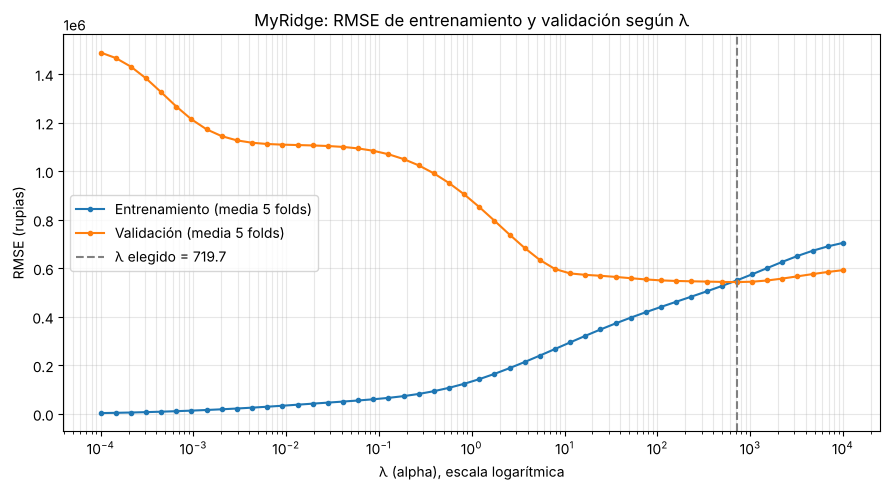

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(lambdas, rmse_tr_mean, marker="o", markersize=3, label="Entrenamiento (media 5 folds)")
ax.plot(lambdas, rmse_val_mean, marker="o", markersize=3, label="Validación (media 5 folds)")
ax.axvline(mejor_lambda, color="gray", linestyle="--", label=f"λ elegido = {mejor_lambda:.1f}")
ax.set_xscale("log")
ax.set_xlabel("λ (alpha), escala logarítmica")
ax.set_ylabel("RMSE (rupias)")
ax.set_title("MyRidge: RMSE de entrenamiento y validación según λ")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura.** Con λ pequeño, el error de entrenamiento es casi 0 y el de validación es alto: hay sobreajuste. Al subir λ, la validación mejora hasta su mínimo en **λ ≈ 720**. Con λ más grande vuelve a empeorar porque el modelo se vuelve demasiado simple. Es el equilibrio entre sesgo y varianza.

### 3.4 Modelo final y RMSE de prueba

In [11]:
modelo_final = MyRidge(alpha=mejor_lambda).fit(X_train_s, y_train)

rmse_train_ridge = modelo_final.rmse(X_train_s, y_train)
rmse_test_ridge = modelo_final.rmse(X_test_s, y_test)            # ← única evaluación en prueba

comparacion_p3 = pd.DataFrame(
    {"RMSE entrenamiento": [rmse_train_p1, rmse_train_ridge],
     "RMSE prueba": [rmse_test_p1, rmse_test_ridge]},
    index=["LinearRegression (Punto 1)", f"MyRidge (λ = {mejor_lambda:.1f})"],
)
comparacion_p3["Prueba / entrenamiento"] = comparacion_p3["RMSE prueba"] / comparacion_p3["RMSE entrenamiento"]
print(comparacion_p3.to_string(float_format=lambda v: f"{v:,.2f}"))
print(f"\nR² de prueba de MyRidge: {modelo_final.score(X_test_s, y_test):.4f}")
print(f"El RMSE de prueba baja {100 * (1 - rmse_test_ridge / rmse_test_p1):.2f} %")

                            RMSE entrenamiento    RMSE prueba  Prueba / entrenamiento
LinearRegression (Punto 1)          471,493.45 219,252,792.00                  465.02
MyRidge (λ = 719.7)                 577,900.05     726,777.51                    1.26

R² de prueba de MyRidge: 0.2023
El RMSE de prueba baja 99.67 %


**Resultado.** El RMSE de prueba baja de ≈ 219 millones a ≈ 727 mil (−99,7 %), y la brecha entre prueba y entrenamiento pasa de 465× a 1,3×. El sobreajuste quedó corregido. El error restante se debe a que solo hay 35 ejemplos para aprender.

### 3.5 Verificación con `sklearn.Ridge`

Se usan los mismos datos y el mismo λ, y se compara con `np.allclose`. La verificación se hace con las 164 features estandarizadas y con las 8 originales sin estandarizar.

Con las 164 polinomiales **sin** estandarizar no se puede verificar: el número de condición es ≈ 10³⁷, y ningún método da un resultado fiable en `float64`.

In [12]:
def verificar_contra_sklearn(X, y, alpha, etiqueta):
    # Entrena ambas implementaciones con los mismos datos y el mismo λ, y compara con np.allclose
    mio = MyRidge(alpha=alpha).fit(X, y)
    sk = Ridge(alpha=alpha).fit(X, y)
    rmse_sk = np.sqrt(mean_squared_error(y, sk.predict(X)))
    checks = {
        "coef_": np.allclose(mio.coef_, sk.coef_),
        "intercept_": np.allclose(mio.intercept_, sk.intercept_),
        "R²": np.allclose(mio.score(X, y), sk.score(X, y)),
        "RMSE": np.allclose(mio.rmse(X, y), rmse_sk),
    }
    print(f"Verificación {etiqueta} (λ = {alpha:.2f})")
    for nombre, ok in checks.items():
        print(f"  {nombre:<11} coincide: {ok}")
    print(f"  R²   MyRidge = {mio.score(X, y):.6f} | sklearn = {sk.score(X, y):.6f}")
    print(f"  RMSE MyRidge = {mio.rmse(X, y):,.4f} | sklearn = {rmse_sk:,.4f}")
    return all(checks.values())

ok_std = verificar_contra_sklearn(X_train_s, y_train, mejor_lambda, "con 164 features ESTANDARIZADAS")
print()
ok_raw = verificar_contra_sklearn(X_train, y_train, mejor_lambda, "con 8 features SIN estandarizar")
print(f"\nTodo coincide en ambos casos: {ok_std and ok_raw}")

# Número de condición de XᵀX + λI (centrado) en cada caso
def condicion(X, lam):
    Xc = X - X.mean(axis=0)
    return np.linalg.cond(Xc.T @ Xc + lam * np.eye(X.shape[1]))

print("\nNúmero de condición de XᵀX + λI:")
print(f"  164 polinomiales estandarizadas : {condicion(X_train_s, mejor_lambda):.1e}")
print(f"  8 originales sin estandarizar   : {condicion(X_train, mejor_lambda):.1e}")
print(f"  164 polinomiales SIN estandarizar: {condicion(X_train_poly, mejor_lambda):.1e}  ← imposible en float64")

Verificación con 164 features ESTANDARIZADAS (λ = 719.69)
  coef_       coincide: True
  intercept_  coincide: True
  R²          coincide: True
  RMSE        coincide: True
  R²   MyRidge = 0.431667 | sklearn = 0.431667
  RMSE MyRidge = 577,900.0541 | sklearn = 577,900.0541

Verificación con 8 features SIN estandarizar (λ = 719.69)
  coef_       coincide: True
  intercept_  coincide: True
  R²          coincide: True
  RMSE        coincide: True
  R²   MyRidge = 0.479815 | sklearn = 0.479815
  RMSE MyRidge = 552,878.9771 | sklearn = 552,878.9771

Todo coincide en ambos casos: True

Número de condición de XᵀX + λI:
  164 polinomiales estandarizadas : 4.0e+00
  8 originales sin estandarizar   : 7.6e+07
  164 polinomiales SIN estandarizar: 6.0e+37  ← imposible en float64


**Conclusión.** `MyRidge` coincide con sklearn en `coef_`, `intercept_`, R² y RMSE, con y sin estandarizar.

## Punto 4 — Ridge vs. Lasso (3 puntos)

- **Ridge (L2)** penaliza $\sum \theta_j^2$: encoge todos los coeficientes, pero ninguno llega a 0.
- **Lasso (L1)** penaliza $\sum |\theta_j|$: lleva varios coeficientes **exactamente a 0**, es decir, selecciona features.

Lasso de sklearn divide el error por 2m, así que su α no es comparable con el de Ridge. Cada uno elige el suyo con `GridSearchCV`, usando los mismos datos estandarizados y los mismos folds del Punto 3.

In [13]:
# Ridge: misma grilla y mismos folds que en el Punto 3
ridge_cv = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("modelo", Ridge())]),
    {"modelo__alpha": np.logspace(-4, 4, 50)},
    scoring="neg_root_mean_squared_error", cv=kfold,
).fit(X_train_poly, y_train)

# Lasso: grilla propia; max_iter alto para que converja
alphas_lasso = np.logspace(1, 6, 50)
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always", ConvergenceWarning)
    lasso_cv = GridSearchCV(
        Pipeline([("scaler", StandardScaler()), ("modelo", Lasso(max_iter=50000))]),
        {"modelo__alpha": alphas_lasso},
        scoring="neg_root_mean_squared_error", cv=kfold,
    ).fit(X_train_poly, y_train)
n_avisos = sum(issubclass(a.category, ConvergenceWarning) for a in avisos)

alpha_ridge = ridge_cv.best_params_["modelo__alpha"]
alpha_lasso = lasso_cv.best_params_["modelo__alpha"]
best_ridge = ridge_cv.best_estimator_.named_steps["modelo"]
best_lasso = lasso_cv.best_estimator_.named_steps["modelo"]

print("=== MEJORES HIPERPARÁMETROS (validación cruzada, 5 folds) ===")
print(f"Ridge (sklearn): α = {alpha_ridge:.4f} | RMSE validación = {-ridge_cv.best_score_:,.0f}")
print(f"Lasso (sklearn): α = {alpha_lasso:,.2f} | RMSE validación = {-lasso_cv.best_score_:,.0f}")
print(f"MyRidge (Punto 3): λ = {mejor_lambda:.4f}  → mismo valor que Ridge: {np.isclose(alpha_ridge, mejor_lambda)}")
print(f"\nConvergenceWarnings de Lasso durante la búsqueda: {n_avisos} (solo en α pequeños, que no se eligen)")

=== MEJORES HIPERPARÁMETROS (validación cruzada, 5 folds) ===
Ridge (sklearn): α = 719.6857 | RMSE validación = 543,027
Lasso (sklearn): α = 95,409.55 | RMSE validación = 551,147
MyRidge (Punto 3): λ = 719.6857  → mismo valor que Ridge: True

ConvergenceWarnings de Lasso durante la búsqueda: 64 (solo en α pequeños, que no se eligen)


### 4.1 Coeficientes lado a lado

In [14]:
coef_df = pd.DataFrame(
    {"MyRidge": modelo_final.coef_, "Ridge (sklearn)": best_ridge.coef_, "Lasso (sklearn)": best_lasso.coef_},
    index=feature_names_poly,
)
coef_df.index.name = "Feature"
coef_df = coef_df.reindex(coef_df["Lasso (sklearn)"].abs().sort_values(ascending=False).index)

print("MyRidge y Ridge de sklearn coinciden:", np.allclose(coef_df["MyRidge"], coef_df["Ridge (sklearn)"]))
with pd.option_context("display.max_rows", 200, "display.float_format", "{:,.2f}".format):
    display(coef_df)

MyRidge y Ridge de sklearn coinciden: True


,MyRidge,Ridge (sklearn),Lasso (sklearn)
Feature,,,
max_power^2 seats,"9,735.06","9,735.06","326,858.58"
km_driven engine seats,"-5,259.87","-5,259.87","-176,052.44"
max_power seats^2,"9,734.62","9,734.62","151,864.51"
year^3,"9,978.80","9,978.80","91,675.02"
max_power,"7,719.44","7,719.44",0.00
seats,"6,877.81","6,877.81",0.00
km_per_year,"-1,370.88","-1,370.88",-0.00
engine_power_ratio,"-4,498.77","-4,498.77",-0.00
year^2,"9,969.02","9,969.02",0.00


### 4.2 Caminos de coeficientes

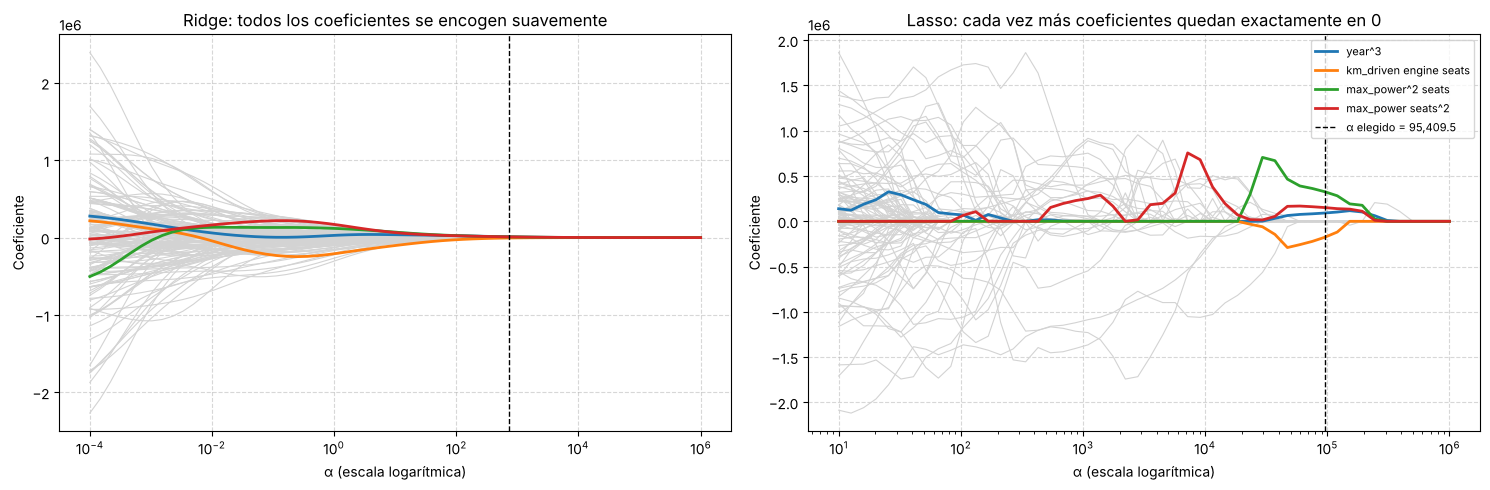

In [15]:
alphas_ridge_path = np.logspace(-4, 6, 60)
ridge_path = np.array([Ridge(alpha=a).fit(X_train_s, y_train).coef_ for a in alphas_ridge_path])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    lasso_path = np.array([Lasso(alpha=a, max_iter=50000).fit(X_train_s, y_train).coef_ for a in alphas_lasso])

seleccionadas = np.flatnonzero(best_lasso.coef_ != 0)                 # índices que Lasso no elimina
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, path, alphas_p, alpha_opt, titulo in [
    (axes[0], ridge_path, alphas_ridge_path, alpha_ridge, "Ridge: todos los coeficientes se encogen suavemente"),
    (axes[1], lasso_path, alphas_lasso, alpha_lasso, "Lasso: cada vez más coeficientes quedan exactamente en 0"),
]:
    ax.plot(alphas_p, np.delete(path, seleccionadas, axis=1), color="lightgray", linewidth=0.8)
    for k in seleccionadas:
        ax.plot(alphas_p, path[:, k], linewidth=2, label=feature_names_poly[k])
    ax.axvline(alpha_opt, color="black", linestyle="--", linewidth=1, label=f"α elegido = {alpha_opt:,.1f}")
    ax.set_xscale("log")
    ax.set_xlabel("α (escala logarítmica)")
    ax.set_ylabel("Coeficiente")
    ax.set_title(titulo)
    ax.grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.** En Ridge, todas las curvas bajan suavemente hacia 0 sin tocarlo. En Lasso, al subir α cada vez más curvas quedan **exactamente** en 0, y con el α elegido solo quedan 4.

### 4.3 Coeficientes en cero y RMSE de prueba

In [16]:
ceros = best_lasso.coef_ == 0
print(f"Lasso deja {ceros.sum()} de {len(ceros)} coeficientes exactamente en 0 y conserva {(~ceros).sum()}:")
for nombre, valor in zip(feature_names_poly[~ceros], best_lasso.coef_[~ceros]):
    print(f"  {nombre:<28} {valor:>12,.0f}")

# ¿Qué features originales quedan fuera por completo? (no aparecen en ningún término conservado)
usadas = {f for nombre in feature_names_poly[~ceros] for f in feature_cols if f in nombre}
print("\nFeatures originales que Lasso elimina por completo:", [f for f in feature_cols if f not in usadas])

rmse_test_ridge_sk = np.sqrt(mean_squared_error(y_test, best_ridge.predict(X_test_s)))
rmse_test_lasso = np.sqrt(mean_squared_error(y_test, best_lasso.predict(X_test_s)))
resumen = pd.DataFrame(
    {"α / λ": [np.nan, mejor_lambda, alpha_ridge, alpha_lasso],
     "Coeficientes ≠ 0": [X_train_poly.shape[1], 164, int((best_ridge.coef_ != 0).sum()), int((~ceros).sum())],
     "RMSE prueba": [rmse_test_p1, rmse_test_ridge, rmse_test_ridge_sk, rmse_test_lasso]},
    index=["LinearRegression (Punto 1)", "MyRidge (Punto 3)", "Ridge (sklearn)", "Lasso (sklearn)"],
)
print()
print(resumen.to_string(float_format=lambda v: f"{v:,.2f}"))

Lasso deja 160 de 164 coeficientes exactamente en 0 y conserva 4:
  year^3                             91,675
  km_driven engine seats           -176,052
  max_power^2 seats                 326,859
  max_power seats^2                 151,865

Features originales que Lasso elimina por completo: ['mileage(km/ltr/kg)', 'km_per_year', 'engine_power_ratio']

                               α / λ  Coeficientes ≠ 0    RMSE prueba
LinearRegression (Punto 1)       NaN               164 219,252,792.00
MyRidge (Punto 3)             719.69               164     726,777.51
Ridge (sklearn)               719.69               164     726,777.51
Lasso (sklearn)            95,409.55                 4     582,942.23


**Resultado.** Lasso elimina **160 de 164** coeficientes y conserva `year³`, `km_driven·engine·seats`, `max_power²·seats` y `max_power·seats²`. Deja fuera por completo `mileage`, `km_per_year` y `engine_power_ratio`. Su RMSE de prueba (≈ 583 mil) es menor que el de Ridge (≈ 727 mil): con tan pocos datos, un modelo con pocas features generaliza mejor.

### 4.4 Por qué Lasso da ceros exactos: la geometría

Ridge y Lasso equivalen a minimizar el error dentro de una región permitida para los coeficientes. Las curvas de nivel del error son elipses.

- **Ridge:** la región es un **círculo**, sin esquinas. La elipse lo toca en un punto cualquiera, casi nunca sobre un eje, así que no aparecen ceros.
- **Lasso:** la región es un **rombo**, con **esquinas sobre los ejes**. La elipse suele tocarlo en una esquina, donde algún coeficiente vale exactamente 0.

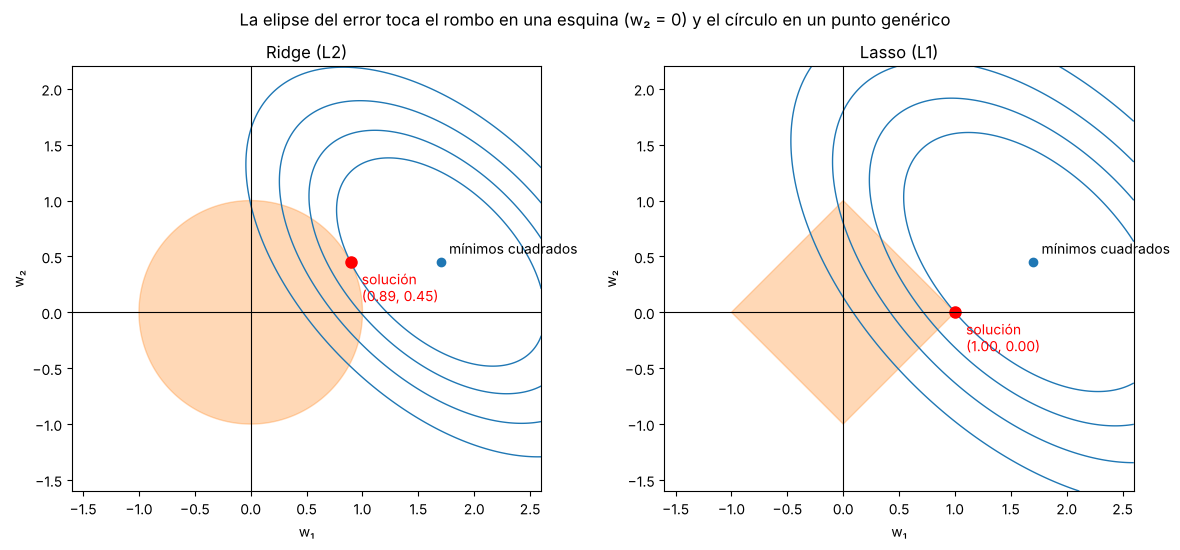

In [17]:
# Ilustración en 2D: elipses del error y regiones permitidas de Ridge (círculo) y Lasso (rombo)
centro = np.array([1.7, 0.45])                                   # solución de mínimos cuadrados (ilustrativa)
A = np.array([[1.0, 0.5], [0.5, 1.0]])                          # forma de las elipses del error
w1, w2 = np.meshgrid(np.linspace(-1.6, 2.6, 400), np.linspace(-1.6, 2.2, 400))
D = np.stack([w1 - centro[0], w2 - centro[1]], axis=-1)
error = np.einsum("...i,ij,...j->...", D, A, D)

theta = np.linspace(0, 2 * np.pi, 4000)
puntos = {"Ridge (L2)": np.c_[np.cos(theta), np.sin(theta)],
          "Lasso (L1)": np.c_[np.cos(theta), np.sin(theta)] / (np.abs(np.cos(theta)) + np.abs(np.sin(theta)))[:, None]}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (nombre, borde) in zip(axes, puntos.items()):
    d = borde - centro
    valores = np.einsum("ni,ij,nj->n", d, A, d)
    toque = borde[np.argmin(valores)]                            # primer punto donde la elipse toca la región
    ax.contour(w1, w2, error, levels=[valores.min() * f for f in (1, 1.6, 2.4, 3.5)], colors="tab:blue", linewidths=1)
    ax.fill(borde[:, 0], borde[:, 1], color="tab:orange", alpha=0.3)
    ax.plot(*centro, "o", color="tab:blue")
    ax.annotate("mínimos cuadrados", centro, textcoords="offset points", xytext=(6, 6))
    ax.plot(*toque, "o", color="red", markersize=8)
    ax.annotate(f"solución\n({toque[0]:.2f}, {toque[1]:.2f})", toque, textcoords="offset points", xytext=(8, -28), color="red")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_aspect("equal")
    ax.set_xlabel("w₁")
    ax.set_ylabel("w₂")
    ax.set_title(nombre)
plt.suptitle("La elipse del error toca el rombo en una esquina (w₂ = 0) y el círculo en un punto genérico")
plt.tight_layout()
plt.show()

## Conclusiones

| Modelo | RMSE de prueba |
|---|---|
| Regresión lineal | ≈ 219 millones |
| MyRidge / Ridge (λ ≈ 720) | ≈ 727 mil |
| Lasso (α ≈ 95 mil, 4 features) | ≈ 583 mil |

La regresión lineal sobreajusta con pocos datos y muchas features. Ridge lo corrige, y `MyRidge` coincide exactamente con sklearn. Lasso además selecciona features, y aquí obtiene el menor error.